# Q3 : un prix de nuitée défendable

> « Pour une demande qui arrive aujourd'hui, on veut un prix de nuitée défendable, cohérent avec la période et l'établissement. »

**Responsable** : Elvis

**Livrable** : `data/clean/grille_tarifaire.csv`, un prix recommandé pour chaque hôtel, chaque mois et chaque type de nuit (32 × 12 × 2 = 768 lignes), plus son erreur moyenne en euros et en pourcentage.

**Plan** : 1. Exploration · 2. Modèle A (régression sur le log du prix) · 3. Variables candidates · 4. Modèle B (forêt aléatoire) · 5. Comparaison en validation croisée · 6. Vérifications · 7. Grille · Fiche réponse

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/clean/valmont_clean.csv")

# Les 6 réservations aberrantes (séjours de 365 nuits, prix nuls) sont exclues
# des analyses. Seule la question 9 les étudie.
df_modele = df[df["flag_anomalie"] == 0].copy()
print(df.shape, df_modele.shape)  # attendu : (800, 23) (794, 23)

(800, 23) (794, 23)


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict

# random_state=42 partout où il y a du hasard : résultats reproductibles
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Ordre fixe des catégories pour que les graphiques se lisent du moins cher au plus cher
ORDRE_CATEGORIES = ["3 étoiles", "4 étoiles", "5 étoiles"]

## 1. Exploration : qu'est-ce qui fait varier le prix ?

On regarde le prix de la nuit selon les quatre variables que le revenue manager connaît **avant** de connaître le client : la catégorie, la ville, le mois et le type de nuit (semaine ou week-end). L'échelle du prix est logarithmique : un écart de 10 % a la même hauteur à 100 € et à 300 €, ce qui prépare le modèle de l'étape 2.

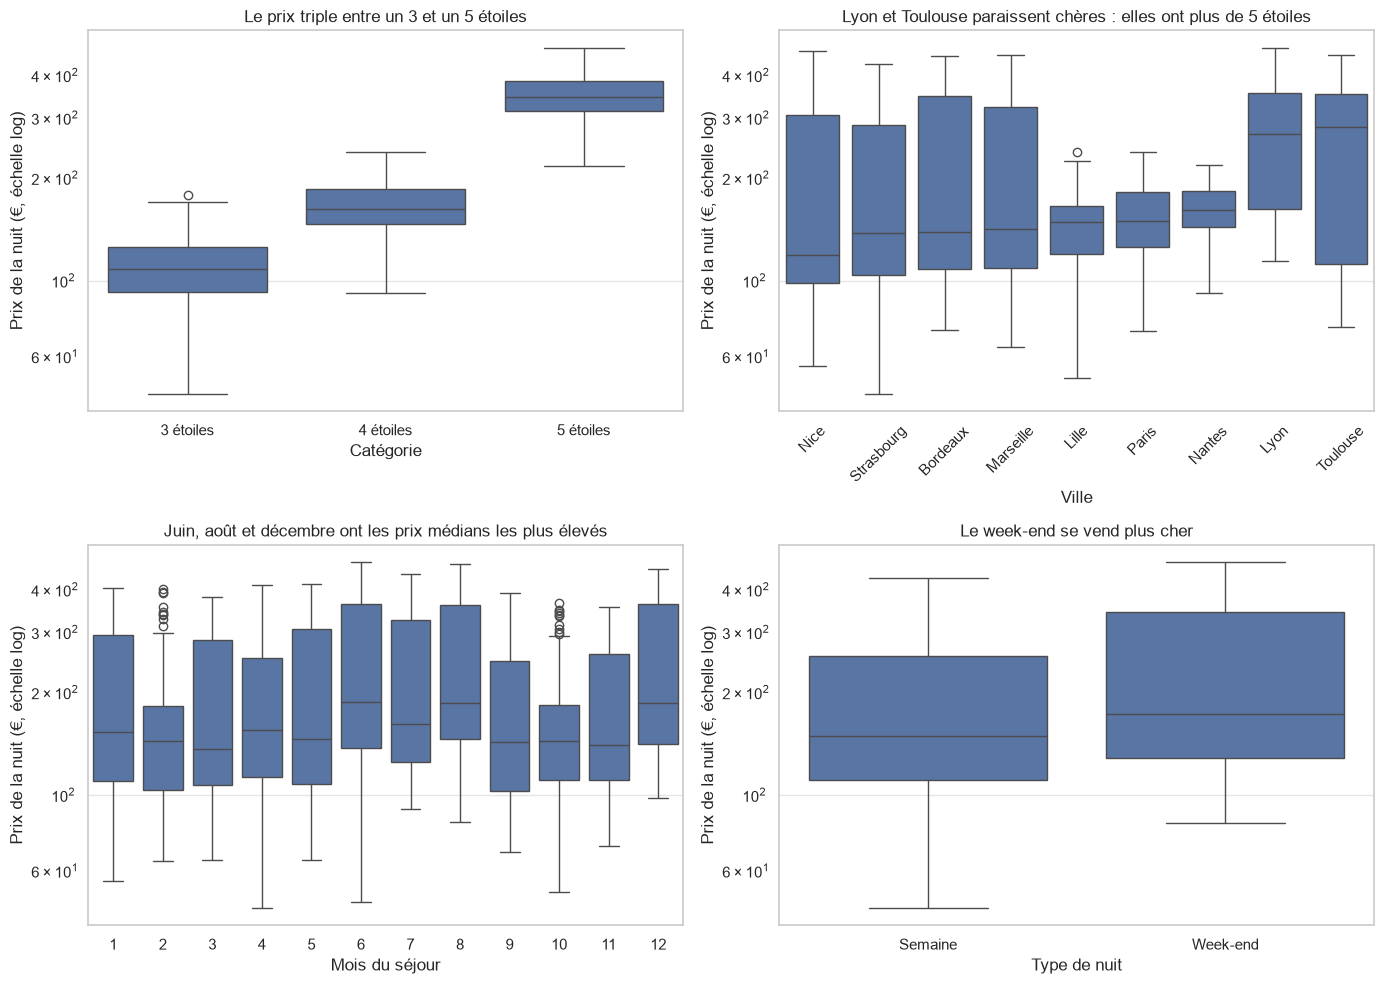

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.boxplot(data=df_modele, x="categorie", y="prix_nuit_eur", order=ORDRE_CATEGORIES, ax=axes[0, 0])
axes[0, 0].set_title("Le prix triple entre un 3 et un 5 étoiles")

# Villes triées par prix médian pour lire le classement d'un coup d'oeil
ordre_villes = df_modele.groupby("ville")["prix_nuit_eur"].median().sort_values().index
sns.boxplot(data=df_modele, x="ville", y="prix_nuit_eur", order=ordre_villes, ax=axes[0, 1])
axes[0, 1].set_title("Lyon et Toulouse paraissent chères : elles ont plus de 5 étoiles")
axes[0, 1].tick_params(axis="x", rotation=45)

sns.boxplot(data=df_modele, x="mois_sejour", y="prix_nuit_eur", ax=axes[1, 0])
axes[1, 0].set_title("Juin, août et décembre ont les prix médians les plus élevés")

sns.boxplot(data=df_modele, x="weekend", y="prix_nuit_eur", ax=axes[1, 1])
axes[1, 1].set_xticks([0, 1], ["Semaine", "Week-end"])
axes[1, 1].set_title("Le week-end se vend plus cher")

etiquettes_x = ["Catégorie", "Ville", "Mois du séjour", "Type de nuit"]
for ax, etiquette in zip(axes.flat, etiquettes_x):
    ax.set_yscale("log")
    ax.set_ylabel("Prix de la nuit (€, échelle log)")
    ax.set_xlabel(etiquette)

plt.tight_layout()
plt.show()

In [4]:
# Repérer les mois chers : prix médian du mois comparé au prix médian global
mediane_globale = df_modele["prix_nuit_eur"].median()
par_mois = (df_modele.groupby("mois_sejour")["prix_nuit_eur"]
            .agg(nb_reservations="size", prix_median="median"))
par_mois["ecart_vs_global_%"] = (par_mois["prix_median"] / mediane_globale - 1) * 100
print(f"Prix médian global : {mediane_globale:.0f} €")
par_mois.round(1)

Prix médian global : 153 €


,nb_reservations,prix_median,ecart_vs_global_%
mois_sejour,,,
1,74,153.1,0.1
2,59,143.9,-5.9
3,72,136.5,-10.7
4,64,155.2,1.5
5,81,145.5,-4.9
6,55,187.5,22.6
7,54,161.2,5.4
8,87,186.0,21.6
9,57,143.0,-6.5


In [5]:
# Attention au mix : une ville paraît chère si elle a beaucoup de 5 étoiles.
# Ce tableau croisé montre quelles catégories existent dans chaque ville.
pd.crosstab(df_modele["ville"], df_modele["categorie"])

categorie,3 étoiles,4 étoiles,5 étoiles
ville,,,
Bordeaux,36,0,28
Lille,25,34,0
Lyon,0,55,66
Marseille,50,20,27
Nantes,0,38,0
Nice,50,0,29
Paris,39,92,0
Strasbourg,86,26,45
Toulouse,20,0,28


**Interprétation**

- **La catégorie domine** : prix médian de 108 € en 3 étoiles, 162 € en 4 étoiles et 345 € en 5 étoiles, avec des boîtes qui se chevauchent à peine.
- **Les mois chers** sont juin, août et décembre, environ 22 % au-dessus du prix médian global (153 €). Mars est le mois le moins cher (−11 %).
- **Le week-end** se vend plus cher (médiane 173 € contre 149 € en semaine).
- **La ville est trompeuse** : Lyon et Toulouse paraissent chères, mais 55 à 58 % de leurs réservations sont en 5 étoiles, et le tableau croisé montre que les villes n'ont pas toutes les mêmes catégories. Ces médianes brutes mélangent l'effet de la ville et celui des étoiles : seul un modèle qui tient compte des deux en même temps peut les séparer. C'est l'objet de l'étape 2.

## 2. Modèle A : régression linéaire sur le logarithme du prix

**Pourquoi le logarithme** : les effets sur un prix sont multiplicatifs (« plus 12 % le week-end », « deux fois plus cher en 5 étoiles »). Le logarithme les rend additifs, donc estimables par une régression linéaire, et chaque coefficient se lit directement en pourcentage : `exp(coefficient) − 1`.

**Variables** : `categorie`, `ville`, `mois_sejour` (traité comme une catégorie, car juin n'est pas « 6 fois janvier ») et `weekend`. Les références sont 3 étoiles, Bordeaux, janvier et nuit de semaine.

On utilise ici `statsmodels` pour avoir le tableau complet (R², p-values) ; la validation croisée de l'étape 5 utilise `scikit-learn` sur exactement les mêmes variables.

In [6]:
modele_a = smf.ols(
    "np.log(prix_nuit_eur) ~ C(categorie) + C(ville) + C(mois_sejour) + weekend",
    data=df_modele,
).fit()

print(f"R² = {modele_a.rsquared:.3f}   R² ajusté = {modele_a.rsquared_adj:.3f}   n = {int(modele_a.nobs)}")

# Lecture en pourcentage : exp(coef) - 1, avec l'intervalle de confiance à 95 %
ic = modele_a.conf_int()
coefs = pd.DataFrame({
    "effet_%": (np.exp(modele_a.params) - 1) * 100,
    "ic_bas_%": (np.exp(ic[0]) - 1) * 100,
    "ic_haut_%": (np.exp(ic[1]) - 1) * 100,
    "p_value": modele_a.pvalues,
}).drop(index="Intercept")
coefs.round(3)

R² = 0.914   R² ajusté = 0.912   n = 794


,effet_%,ic_bas_%,ic_haut_%,p_value
C(categorie)[T.4 étoiles],53.698,49.006,58.538,0.000
C(categorie)[T.5 étoiles],223.491,214.371,232.875,0.000
C(ville)[T.Lille],-1.600,-7.052,4.172,0.579
C(ville)[T.Lyon],-2.418,-7.077,2.475,0.326
C(ville)[T.Marseille],1.189,-3.617,6.234,0.634
C(ville)[T.Nantes],-3.583,-9.903,3.180,0.291
C(ville)[T.Nice],-2.438,-7.278,2.656,0.341
C(ville)[T.Paris],0.804,-4.132,5.994,0.754
C(ville)[T.Strasbourg],-1.290,-5.637,3.258,0.572
C(ville)[T.Toulouse],-1.423,-6.937,4.417,0.625


In [7]:
# Prix de référence : 3 étoiles, Bordeaux, janvier, semaine (exp de la constante)
print(f"Prix de référence (3*, Bordeaux, janvier, semaine) : {np.exp(modele_a.params['Intercept']):.0f} €")

# Test global de chaque bloc de variables (ANOVA de type II) : chaque bloc compte-t-il ?
import statsmodels.api as sm
sm.stats.anova_lm(modele_a, typ=2).round(4)

Prix de référence (3*, Bordeaux, janvier, semaine) : 96 €


,sum_sq,df,F,PR(>F)
C(categorie),150.5125,2.0,3251.4530,0.0000
C(ville),0.1615,8.0,0.8723,0.5395
C(mois_sejour),7.4941,11.0,29.4348,0.0000
weekend,2.7037,1.0,116.8151,0.0000
Residual,17.8451,771.0,NaN,NaN


**Interprétation**

Le modèle explique **91 % de la variance du log du prix** (R² = 0,914). Toutes choses égales par ailleurs :

| Effet | Lecture |
| --- | --- |
| 4 étoiles | **+54 %** par rapport à un 3 étoiles |
| 5 étoiles | **+223 %**, soit un prix multiplié par 3,2 |
| Juin, juillet, août, décembre | **+23 à +24 %** par rapport à janvier |
| Week-end | **+14 %** par rapport à une nuit de semaine |
| Ville | aucun effet significatif (de −4 % à +1 %, test global p = 0,54) |
| Autres mois | aucun écart significatif avec janvier |

Deux surprises que le modèle corrige par rapport à l'exploration :

1. **Juillet est aussi un mois de haute saison** (+24 %). Son prix médian brut paraissait bas (161 €), parce que la moitié de ses réservations sont en 3 étoiles, contre 39 % sur l'année.
2. **La ville ne joue pas** : à catégorie égale, un hôtel coûte le même prix à Paris et à Nice. Les écarts vus à l'étape 1 venaient du mix d'étoiles.

Le prix se résume donc à **trois leviers : la catégorie, la haute saison et le week-end**.

## 3. Le protocole de comparaison et les variables candidates

Pour comparer des modèles honnêtement, chaque réservation est prédite par un modèle **qui ne l'a pas vue** : validation croisée à 5 plis, `KFold(n_splits=5, shuffle=True, random_state=42)`. Les mêmes plis serviront en Q4.

Les erreurs sont calculées **en euros** (on repasse par `exp`), parce que c'est ce que comprend un directeur :
- **MAE** : erreur absolue moyenne, en euros par nuit ;
- **MAPE** : erreur absolue moyenne en pourcentage du prix réel.

Ensuite on teste si `segment_declare`, `canal` ou `nb_personnes` améliorent l'erreur. On ne les garde que si le gain est net, **car un prix doit pouvoir se fixer avant de connaître le client**.

In [8]:
VARIABLES_BASE = ["categorie", "ville", "mois_sejour", "weekend"]
VARIABLES_CATEGORIELLES = ["categorie", "ville", "mois_sejour", "segment_declare", "canal"]

plis = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_log = np.log(df_modele["prix_nuit_eur"])
prix_reel = df_modele["prix_nuit_eur"]


def construire_pipeline(variables, estimateur):
    """Encode les variables catégorielles en indicatrices (une modalité de référence
    retirée pour éviter la colinéarité) et laisse passer les numériques telles quelles."""
    cat = [v for v in variables if v in VARIABLES_CATEGORIELLES]
    preparation = ColumnTransformer(
        [("indicatrices", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)],
        remainder="passthrough",
    )
    return Pipeline([("preparation", preparation), ("modele", estimateur)])


def evaluer(variables, estimateur):
    """Prédictions hors échantillon sur le log du prix, puis erreurs en euros."""
    pipeline = construire_pipeline(variables, estimateur)
    prix_predit = np.exp(cross_val_predict(pipeline, df_modele[variables], y_log, cv=plis))
    erreur = (prix_reel - prix_predit).abs()
    return {"MAE_€": erreur.mean(), "MAPE_%": (erreur / prix_reel).mean() * 100}

In [9]:
resultats = {"Modèle A (base)": evaluer(VARIABLES_BASE, LinearRegression())}
for candidate in ["segment_declare", "canal", "nb_personnes"]:
    resultats[f"A + {candidate}"] = evaluer(VARIABLES_BASE + [candidate], LinearRegression())
# Contre-test : la ville, non significative à l'étape 2, sert-elle en prédiction ?
resultats["A sans ville"] = evaluer(["categorie", "mois_sejour", "weekend"], LinearRegression())

candidats = pd.DataFrame(resultats).T
candidats["gain_MAE_€"] = candidats.loc["Modèle A (base)", "MAE_€"] - candidats["MAE_€"]
candidats.round(2)

,MAE_€,MAPE_%,gain_MAE_€
Modèle A (base),19.09,11.97,0.00
A + segment_declare,17.03,10.70,2.06
A + canal,18.33,11.62,0.76
A + nb_personnes,17.76,11.19,1.33
A sans ville,18.89,11.83,0.19


**Interprétation et décision**

- `segment_declare` fait gagner 2,06 € d'erreur moyenne (de 11,97 % à 10,70 %), `nb_personnes` 1,33 € et `canal` 0,76 €.
- **Aucune n'est retenue.** Le gain le plus fort est de 2 € sur 19 €, alors qu'une grille doit fixer un prix **avant** de connaître le client : on ne sait ni son segment ni son canal quand on affiche un tarif. En plus, le segment déclaré est jugé peu fiable par la direction, et la Q7 le confirme (accord de 0,37 seulement avec les vrais types de séjours).
- **Retirer la ville** change l'erreur de 0,19 € seulement, ce qui est négligeable. On garde le modèle A prévu par la fiche, pour que les plis et les variables restent les mêmes en Q4. On retient tout de même le message pour la direction : la localisation ne justifie aucun écart de prix.

## 4 et 5. Modèle B : forêt aléatoire, et comparaison en validation croisée

Même variables, mêmes plis, même cible (log du prix) : seule la méthode change. La forêt peut capter des interactions (par exemple « le week-end compte plus en 5 étoiles ») que la régression additive ignore. Si elle ne gagne que quelques euros, on garde la régression, lisible et défendable devant un directeur.

In [10]:
comparaison = pd.DataFrame({
    "Modèle A : régression sur log(prix)": evaluer(VARIABLES_BASE, LinearRegression()),
    "Modèle B : forêt aléatoire": evaluer(VARIABLES_BASE, RandomForestRegressor(random_state=RANDOM_STATE)),
}).T
comparaison.round(2)

,MAE_€,MAPE_%
Modèle A : régression sur log(prix),19.09,11.97
Modèle B : forêt aléatoire,21.19,13.41


In [11]:
# La forêt sur-apprend-elle ? On compare son erreur sur les données d'entraînement
# et en validation croisée : un grand écart signale qu'elle mémorise le bruit.
foret = construire_pipeline(VARIABLES_BASE, RandomForestRegressor(random_state=RANDOM_STATE))
foret.fit(df_modele[VARIABLES_BASE], y_log)
erreur_entrainement = (prix_reel - np.exp(foret.predict(df_modele[VARIABLES_BASE]))).abs().mean()
print(f"Forêt : MAE sur l'entraînement = {erreur_entrainement:.2f} € "
      f"contre {comparaison.iloc[1, 0]:.2f} € en validation croisée")

Forêt : MAE sur l'entraînement = 13.76 € contre 21.19 € en validation croisée


**Interprétation et choix du modèle**

La forêt aléatoire **fait moins bien** que la régression : 21,19 € d'erreur moyenne (13,4 %) contre 19,09 € (12,0 %). Elle sur-apprend : 13,76 € d'erreur sur les données qu'elle a vues contre 21,19 € sur celles qu'elle n'a pas vues. Avec 794 réservations et des effets simples et multiplicatifs, elle n'a pas d'interaction utile à découvrir et mémorise du bruit.

**On retient le modèle A** : il est plus précis, et chaque prix se décompose en pourcentages qu'un directeur peut vérifier. Même à précision égale on l'aurait gardé, parce qu'il est lisible et défendable.

## 6. Vérifications du modèle A

1. **Résidus contre prix prédit** : aucune forme particulière (pas d'entonnoir, pas de courbe). Sinon le modèle se tromperait systématiquement sur une gamme de prix.
2. **Résidu moyen par hôtel** : aucun hôtel ne doit être systématiquement sur- ou sous-estimé. On utilise les prédictions **hors échantillon** pour ne pas se rassurer à tort.

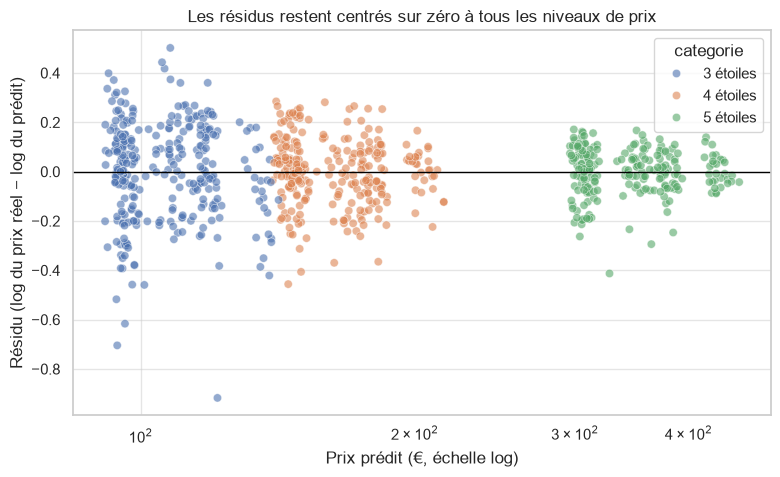

In [12]:
modele_a_cv = construire_pipeline(VARIABLES_BASE, LinearRegression())
log_predit = cross_val_predict(modele_a_cv, df_modele[VARIABLES_BASE], y_log, cv=plis)
df_modele["prix_predit_cv"] = np.exp(log_predit)
# Résidu en log ≈ écart en % : +0,10 veut dire un prix réel environ 10 % au-dessus de la grille
df_modele["residu_log"] = y_log - log_predit

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df_modele, x="prix_predit_cv", y="residu_log", hue="categorie",
                hue_order=ORDRE_CATEGORIES, alpha=0.6, ax=ax)
ax.axhline(0, color="black", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Prix prédit (€, échelle log)")
ax.set_ylabel("Résidu (log du prix réel − log du prédit)")
ax.set_title("Les résidus restent centrés sur zéro à tous les niveaux de prix")
plt.show()

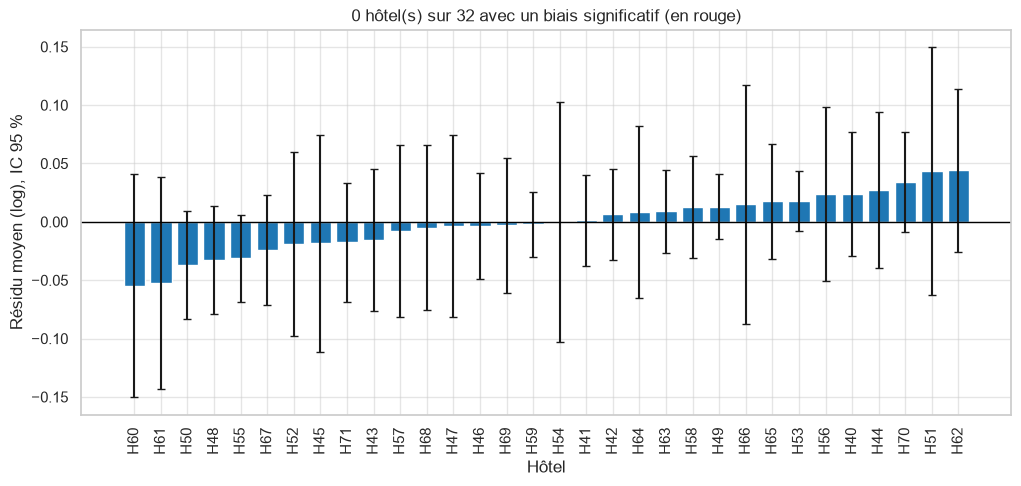

Hôtels dont l'intervalle exclut zéro : 0
Écart moyen par hôtel : de -5.3 % à +4.5 %


categorie
3 étoiles    0.201
4 étoiles    0.134
5 étoiles    0.094
Name: residu_log, dtype: float64

In [13]:
# Résidu moyen par hôtel, avec un intervalle de confiance à 95 %
par_hotel = (df_modele.groupby(["hotel_id", "categorie", "ville"])["residu_log"]
             .agg(n="size", moyenne="mean", ecart_type="std").reset_index())
par_hotel["demi_ic"] = 1.96 * par_hotel["ecart_type"] / np.sqrt(par_hotel["n"])
par_hotel["ecart_%"] = (np.exp(par_hotel["moyenne"]) - 1) * 100
# Un hôtel est « systématiquement » mal estimé si son intervalle ne contient pas 0
par_hotel["biais_significatif"] = (par_hotel["moyenne"].abs() > par_hotel["demi_ic"])

par_hotel = par_hotel.sort_values("moyenne")
fig, ax = plt.subplots(figsize=(12, 5))
couleurs = np.where(par_hotel["biais_significatif"], "tab:red", "tab:blue")
ax.bar(par_hotel["hotel_id"], par_hotel["moyenne"], yerr=par_hotel["demi_ic"], color=couleurs, capsize=3)
ax.axhline(0, color="black", lw=1)
ax.set_xlabel("Hôtel")
ax.set_ylabel("Résidu moyen (log), IC 95 %")
ax.tick_params(axis="x", rotation=90)
nb_biaises = par_hotel["biais_significatif"].sum()
ax.set_title(f"{nb_biaises} hôtel(s) sur 32 avec un biais significatif (en rouge)")
plt.show()

print(f"Hôtels dont l'intervalle exclut zéro : {nb_biaises}")
print(f"Écart moyen par hôtel : de {par_hotel['ecart_%'].min():+.1f} % à {par_hotel['ecart_%'].max():+.1f} %")
# Dispersion des résidus par catégorie : le modèle est-il aussi précis partout ?
df_modele.groupby("categorie")["residu_log"].std().round(3)

**Interprétation**

- **Résidus contre prix prédit** : le nuage reste centré sur zéro à tous les niveaux de prix, sans courbe. Le modèle ne se trompe pas systématiquement sur une gamme de prix.
- **Aucun hôtel n'est systématiquement sur- ou sous-estimé** : les 32 intervalles de confiance contiennent zéro, et les écarts moyens vont de −5 % à +4,5 %.
- **La précision varie selon la catégorie** : l'écart-type des résidus est de 0,20 en 3 étoiles (environ ±20 %), contre 0,13 en 4 étoiles et 0,09 en 5 étoiles. Les prix des 3 étoiles sont plus dispersés autour de la grille. C'est à creuser en Q4 et c'est une limite à signaler.

## 7. La grille tarifaire

Le modèle A est réentraîné sur les 794 réservations, puis on prédit un prix pour chaque hôtel × mois × type de nuit : 32 × 12 × 2 = **768 lignes**. Le prix est arrondi à l'euro : c'est un tarif affiché, pas un calcul.

In [14]:
# Modèle final : mêmes variables, entraîné sur toutes les réservations valides
modele_final = construire_pipeline(VARIABLES_BASE, LinearRegression())
modele_final.fit(df_modele[VARIABLES_BASE], y_log)

# Référentiel des 32 hôtels (chaque hôtel a une seule catégorie et une seule ville)
hotels = df_modele[["hotel_id", "categorie", "ville"]].drop_duplicates().sort_values("hotel_id")
assert len(hotels) == 32 and hotels["hotel_id"].is_unique

# Produit cartésien hôtels x 12 mois x {semaine, week-end}
periodes = pd.MultiIndex.from_product([range(1, 13), [0, 1]], names=["mois_sejour", "weekend"]).to_frame(index=False)
grille = hotels.merge(periodes, how="cross")

# Arrondi à l'euro : c'est un tarif affiché, pas un calcul
grille["prix_recommande"] = np.exp(modele_final.predict(grille[VARIABLES_BASE])).round(0)
grille = grille[["hotel_id", "categorie", "ville", "mois_sejour", "weekend", "prix_recommande"]]

print(grille.shape)  # attendu : (768, 6)
grille.head(6)

(768, 6)


,hotel_id,categorie,ville,mois_sejour,weekend,prix_recommande
0,H40,4 étoiles,Paris,1,0,149.0
1,H40,4 étoiles,Paris,1,1,169.0
2,H40,4 étoiles,Paris,2,0,152.0
3,H40,4 étoiles,Paris,2,1,173.0
4,H40,4 étoiles,Paris,3,0,150.0
5,H40,4 étoiles,Paris,3,1,170.0


In [15]:
# Vérification : hiérarchie des catégories, ville par ville, mois par mois, nuit par nuit.
# Pour chaque combinaison, le prix le plus bas d'une catégorie supérieure doit dépasser
# le prix le plus haut de la catégorie inférieure.
rang = {c: i for i, c in enumerate(ORDRE_CATEGORIES)}
violations = []
for (ville, mois, we), bloc in grille.groupby(["ville", "mois_sejour", "weekend"]):
    prix_par_cat = bloc.groupby("categorie")["prix_recommande"].agg(["min", "max"])
    cats = sorted(prix_par_cat.index, key=rang.get)
    for basse, haute in zip(cats, cats[1:]):
        if prix_par_cat.loc[haute, "min"] < prix_par_cat.loc[basse, "max"]:
            violations.append((ville, mois, we, basse, haute))

print(f"Combinaisons ville x mois x nuit contrôlées : {grille.groupby(['ville','mois_sejour','weekend']).ngroups}")
print(f"Violations de la hiérarchie des catégories : {len(violations)}")

Combinaisons ville x mois x nuit contrôlées : 216
Violations de la hiérarchie des catégories : 0


           médiane_réelle_€  médiane_grille_€
categorie                                    
3 étoiles             108.0             108.0
4 étoiles             162.0             167.0
5 étoiles             345.0             350.0


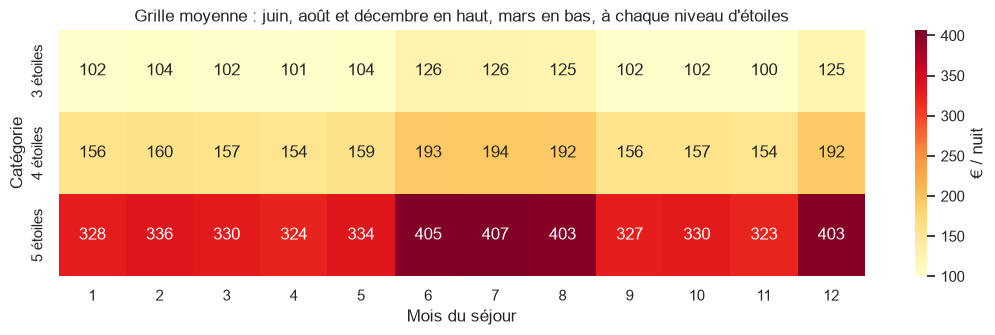

In [16]:
# Contrôle de cohérence : la grille reproduit-elle les médianes connues par catégorie ?
comparaison_medianes = pd.DataFrame({
    "médiane_réelle_€": df_modele.groupby("categorie")["prix_nuit_eur"].median(),
    "médiane_grille_€": grille.groupby("categorie")["prix_recommande"].median(),
}).round(0)
print(comparaison_medianes)

# Vue de lecture pour le revenue manager : prix moyen de la grille par catégorie et par mois
vue = grille.pivot_table(index="categorie", columns="mois_sejour", values="prix_recommande", aggfunc="mean").round(0)
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(vue, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "€ / nuit"}, ax=ax)
ax.set_xlabel("Mois du séjour")
ax.set_ylabel("Catégorie")
ax.set_title("Grille moyenne : juin, août et décembre en haut, mars en bas, à chaque niveau d'étoiles")
plt.show()

In [17]:
grille.to_csv("../data/clean/grille_tarifaire.csv", index=False)
print("Exporté : data/clean/grille_tarifaire.csv", grille.shape)

Exporté : data/clean/grille_tarifaire.csv (768, 6)


**Interprétation et règle de lecture pour le revenue manager**

La grille compte 768 prix, un par hôtel, par mois et par type de nuit. Elle respecte la hiérarchie des catégories dans les 216 combinaisons ville × mois × nuit contrôlées (0 violation), et elle retrouve les médianes connues : 108 € en 3 étoiles, 167 € en 4 étoiles (162 € observé) et 350 € en 5 étoiles (345 € observé).

**Règle de lecture** :
1. Lire le prix de l'hôtel pour le mois et le type de nuit demandés.
2. Ce prix intègre déjà la haute saison (+23 à +24 % en juin, juillet, août et décembre) et le week-end (+14 %).
3. **Marge de tolérance de ±12 %** (l'erreur moyenne du modèle, environ ±19 € par nuit). Un prix accordé dans cette fourchette est défendable. En dessous, il faut le justifier par écrit (client grand compte, dernière chambre à écouler…).
4. En 3 étoiles la dispersion est plus forte (environ ±20 %) : la grille y sert de repère plutôt que de prix ferme.

## Ordre de grandeur du gain

Combien de revenu laisse-t-on aujourd'hui en vendant nettement **sous** la grille ? On prend les réservations **honorées** dont le prix réel est inférieur au prix prédit (hors échantillon) de plus que l'erreur moyenne du modèle, et on calcule ce qu'aurait rapporté une vente au plancher de la tolérance (grille − erreur moyenne). C'est une **borne haute** : elle suppose que le client aurait réservé quand même au prix plus élevé.

In [18]:
mape = comparaison.iloc[0]["MAPE_%"] / 100
honorees = df_modele[df_modele["a_annule"] == 0].copy()
plancher = honorees["prix_predit_cv"] * (1 - mape)
sous_grille = honorees["prix_nuit_eur"] < plancher
manque_par_nuit = (plancher - honorees["prix_nuit_eur"]).where(sous_grille, 0)
manque_total = (manque_par_nuit * honorees["nb_nuits"]).sum()
ca_honore = (honorees["prix_nuit_eur"] * honorees["nb_nuits"]).sum()

print(f"Réservations honorées : {len(honorees)}")
print(f"Vendues sous le plancher de la grille : {sous_grille.sum()} ({sous_grille.mean():.0%})")
print(f"Manque à gagner sur l'échantillon : {manque_total:,.0f} € "
      f"soit {manque_total / ca_honore:.1%} du chiffre d'affaires honoré ({ca_honore:,.0f} €)")

Réservations honorées : 587
Vendues sous le plancher de la grille : 91 (16%)
Manque à gagner sur l'échantillon : 2,900 € soit 0.9% du chiffre d'affaires honoré (338,948 €)


**Interprétation**

Sur les 587 réservations honorées, **91 (16 %)** ont été vendues sous le plancher de la grille (prix prédit moins 12 %). Les ramener au plancher aurait rapporté **environ 2 900 €** sur l'échantillon, soit **0,9 % du chiffre d'affaires honoré**. C'est une borne haute, puisqu'on suppose que ces clients auraient réservé quand même.

Le gain direct est modeste. La valeur principale de la grille est ailleurs : elle remplace l'intuition par un prix reproductible et justifiable, et elle sert de base à la Q4 (correction par période) et aux primes ou remises par type de séjour de la synthèse.

## Fiche réponse Q3

1. **Compréhension** : la direction veut un tarif de nuitée que le revenue manager peut appliquer et justifier dès qu'une demande arrive, sans connaître le client, cohérent avec l'hôtel et la période.

2. **Méthode** : régression linéaire sur le logarithme du prix, avec la catégorie, la ville, le mois (en catégorie) et le week-end. Le logarithme rend additifs des effets multiplicatifs et donne des coefficients lisibles en pourcentage. Elle a été comparée à une forêt aléatoire en validation croisée à 5 plis (`random_state=42`), avec des erreurs calculées en euros. La forêt est moins précise (21,19 € contre 19,09 €) et sur-apprend. Le segment, le canal et le nombre de personnes ont été écartés : leur gain est faible (2 € au plus) et ils ne sont pas connus au moment de fixer un prix.

3. **Vérifications** : erreurs hors échantillon uniquement ; résidus sans forme selon le prix prédit ; aucun des 32 hôtels avec un biais significatif ; hiérarchie des catégories respectée dans 216 combinaisons sur 216 ; médianes de la grille cohérentes avec les médianes observées.

4. **Résultat** : une grille de 768 prix (`data/clean/grille_tarifaire.csv`), avec une **erreur moyenne de 19,09 € par nuit, soit 12,0 %**. Le prix tient en trois leviers : 4 étoiles +54 %, 5 étoiles +223 % ; haute saison (juin, juillet, août, décembre) +23 à +24 % ; week-end +14 %. La ville n'a aucun effet à catégorie égale.

5. **Décision** : Valmont affiche le prix de la grille pour chaque demande, avec une tolérance de ±12 %. Tout prix accordé en dessous est justifié par écrit. Juillet passe en tarif de haute saison au même titre que juin, août et décembre.

6. **Gain** : 16 % des réservations honorées ont été vendues sous le plancher de la grille. Les ramener au plancher représente au plus environ 2 900 € sur l'échantillon (0,9 % du chiffre d'affaires honoré). Le gain principal reste la cohérence : un prix reproductible et défendable, base de la Q4 et des conditions par type de séjour.

7. **Limites et axes d'amélioration** :
   - La précision est plus faible en 3 étoiles (environ ±20 %) : il faudrait ajouter des caractéristiques propres aux hôtels ou une correction par hôtel quand les données le permettront.
   - Le modèle prédit le prix médian d'un profil (retour par `exp` du log) : il est légèrement sous la moyenne. Une correction de retransformation (smearing de Duan) est possible.
   - La grille reproduit les prix pratiqués, pas le prix optimal : sans données de demande refusée, on ne peut pas mesurer l'élasticité au prix.
   - Les effectifs par mois et par catégorie sont faibles (14 à 39 réservations par hôtel) : la Q4 dira sur quels mois la grille est fiable.